# Étape 8 : Interprétabilité des modèles
Objectif : comprendre sur quoi reposent les décisions des modèles.
- **Grad-CAM** : zones de l'image qui influencent la décision de l'architecture complète (A7).
- **SHAP** : caractéristiques de couleur et de texture qui pèsent le plus dans la décision du modèle de machine learning.
- **Règles floues** : lecture des règles apprises par la couche ANFIS de A7.

In [ ]:
#les couches personnalisées

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"     # moins de messages techniques de TensorFlow
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, ops

class AjoutPosition(layers.Layer):
    def build(self, forme):
        self.positions = self.add_weight(shape=(1, forme[1], forme[2]), initializer="random_normal", name="positions")
    def call(self, x):
        return x + self.positions

class CoucheANFIS(layers.Layer):
    def __init__(self, nb_regles=12, nb_sorties=3, **kwargs):
        super().__init__(**kwargs)
        self.nb_regles = nb_regles
        self.nb_sorties = nb_sorties
    def build(self, forme):
        d = forme[-1]
        self.centres = self.add_weight(shape=(self.nb_regles, d), initializer="random_normal", name="centres")
        self.log_sigmas = self.add_weight(shape=(self.nb_regles, d), initializer="zeros", name="log_sigmas")
        self.A = self.add_weight(shape=(self.nb_regles, d, self.nb_sorties), initializer="glorot_uniform", name="A")
        self.b = self.add_weight(shape=(self.nb_regles, self.nb_sorties), initializer="zeros", name="b")
    def forces(self, x):
        ecart = (ops.expand_dims(x, 1) - self.centres) / ops.exp(self.log_sigmas)
        return ops.softmax(-0.5 * ops.sum(ops.square(ecart), axis=-1), axis=-1)
    def call(self, x):
        w = self.forces(x)
        y_regles = ops.einsum("bd,rdk->brk", x, self.A) + self.b
        return ops.sum(ops.expand_dims(w, -1) * y_regles, axis=1)
    def get_config(self):
        config = super().get_config()
        config.update(nb_regles=self.nb_regles, nb_sorties=self.nb_sorties)
        return config

In [2]:
#données et modèle A7

donnees = np.load("../data/donnees_feves.npz")
X, y = donnees["X"].astype("float32"), donnees["y"]
df = pd.read_csv("../results/tables/02_decoupage.csv")
idx_test = np.where(df["partition"] == "test")[0]
classes = ["category 1", "category 2", "category 3"]

modele_a7 = keras.models.load_model("../models/A7_architecture_complete.keras",
                                    custom_objects={"CoucheANFIS": CoucheANFIS, "AjoutPosition": AjoutPosition})

proba_test = modele_a7.predict(X[idx_test], verbose=0)
pred_test = proba_test.argmax(axis=1)
y_test = y[idx_test]

from sklearn.metrics import f1_score
print("F1 macro de A7 sur le test :", round(f1_score(y_test, pred_test, average="macro"), 4))

F1 macro de A7 sur le test : 0.9498


In [3]:
#la fonction Grad-CAM

# Dernière carte de convolution : l'entrée du dernier MaxPooling, juste avant le passage aux tokens
position_reshape = [i for i, c in enumerate(modele_a7.layers) if isinstance(c, layers.Reshape)][0]
derniere_conv = modele_a7.layers[position_reshape - 1].input        # forme (15, 15, 128)
modele_gradcam = keras.Model(modele_a7.inputs, [derniere_conv, modele_a7.output])

def grad_cam(image, classe=None):
    x = tf.convert_to_tensor(image[None])
    with tf.GradientTape() as enregistreur:
        cartes, proba = modele_gradcam(x, training=False)
        if classe is None:
            classe = int(tf.argmax(proba[0]))
        score = proba[:, classe]
    gradients = enregistreur.gradient(score, cartes)               # effet de chaque carte sur le score
    poids = tf.reduce_mean(gradients, axis=(1, 2))                 # importance de chacune des 128 cartes
    cam = tf.nn.relu(tf.reduce_sum(cartes * poids[:, None, None, :], axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)                                 # entre 0 et 1
    cam = tf.image.resize(cam[..., None], (60, 60)).numpy()[..., 0]
    return cam, classe, proba[0].numpy()

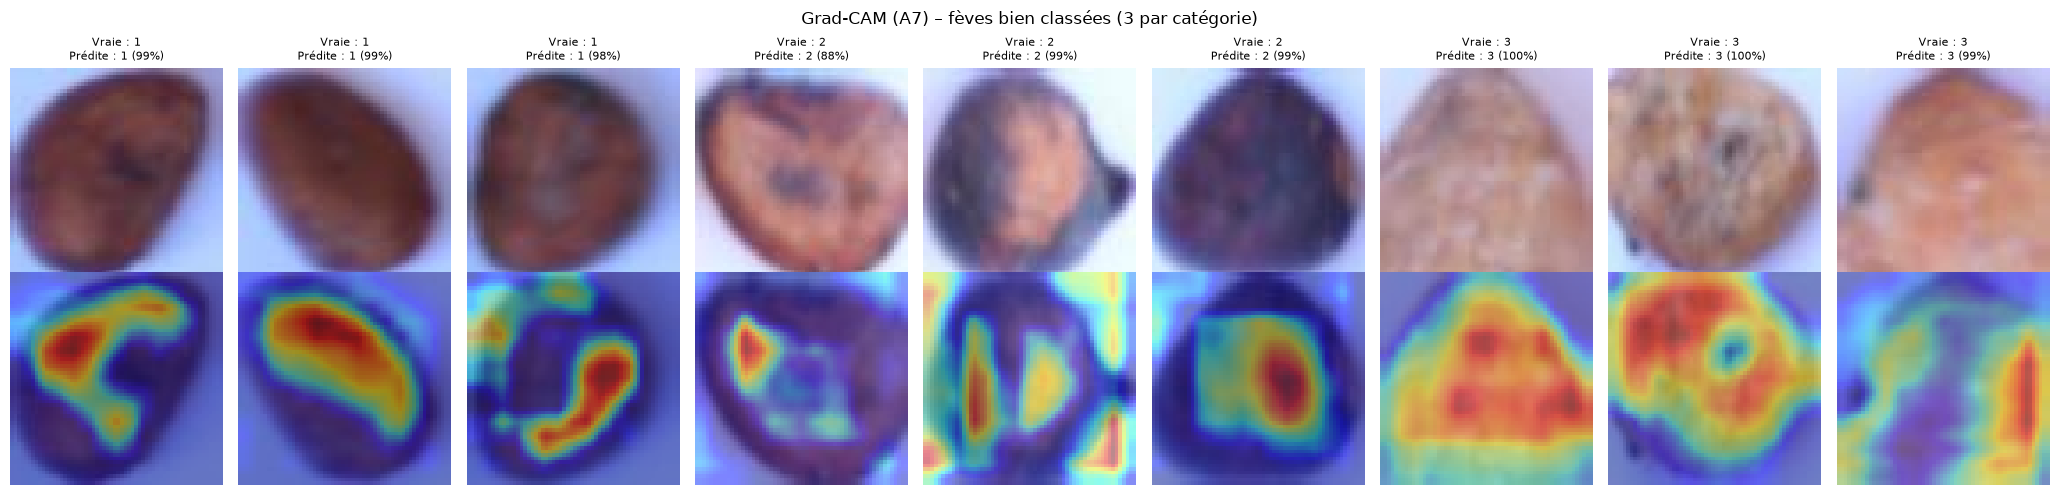

Erreurs 1 -> 2 : 42 | Erreurs 2 -> 1 : 12 | Autres erreurs : 0


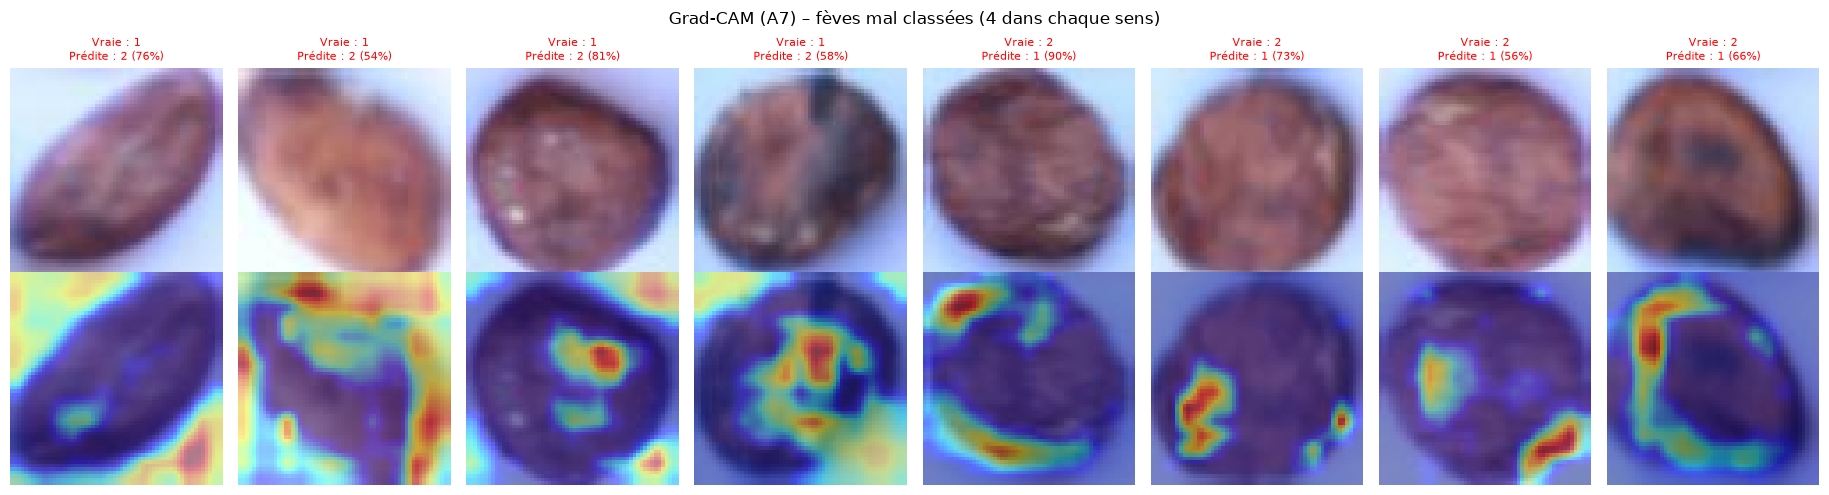

In [5]:
#Grad-CAM sur des fèves bien classées, puis sur des erreurs

def afficher_gradcam(indices, titre, fichier):
    fig, axes = plt.subplots(2, len(indices), figsize=(2.3 * len(indices), 5))
    for col, i in enumerate(indices):
        image = X[idx_test[i]]
        cam, classe, proba = grad_cam(image)
        axes[0, col].imshow(image.astype("uint8"))
        axes[0, col].set_title(f"Vraie : {classes[y_test[i]][-1]}\nPrédite : {classes[classe][-1]} ({proba[classe]:.0%})",
                               fontsize=8, color="black" if classe == y_test[i] else "red")
        axes[1, col].imshow(image.astype("uint8"))
        axes[1, col].imshow(cam, cmap="jet", alpha=0.45)
        for ligne in range(2):
            axes[ligne, col].axis("off")
    plt.suptitle(titre)
    plt.tight_layout()
    plt.savefig(f"../results/figures/{fichier}", dpi=150)
    plt.show()

rng = np.random.default_rng(42)
bien_classees = np.concatenate([rng.choice(np.where((y_test == c) & (pred_test == c))[0], 3, replace=False)
                                for c in range(3)])
erreurs = np.where(pred_test != y_test)[0]

afficher_gradcam(bien_classees, "Grad-CAM (A7) – fèves bien classées (3 par catégorie)", "08_gradcam_correctes.png")
# Erreurs des deux sens : 4 fèves "1 prédite 2" et 4 fèves "2 prédite 1"
erreurs_1_vers_2 = np.where((y_test == 0) & (pred_test == 1))[0]
erreurs_2_vers_1 = np.where((y_test == 1) & (pred_test == 0))[0]
print("Erreurs 1 -> 2 :", len(erreurs_1_vers_2), "| Erreurs 2 -> 1 :", len(erreurs_2_vers_1),
      "| Autres erreurs :", len(erreurs) - len(erreurs_1_vers_2) - len(erreurs_2_vers_1))
choix_erreurs = np.concatenate([rng.choice(erreurs_1_vers_2, min(4, len(erreurs_1_vers_2)), replace=False),
                                rng.choice(erreurs_2_vers_1, min(4, len(erreurs_2_vers_1)), replace=False)])
afficher_gradcam(choix_erreurs, "Grad-CAM (A7) – fèves mal classées (4 dans chaque sens)", "08_gradcam_erreurs.png")

**Grad-CAM (A7) :**
- Pour les fèves bien classées, l'attention se situe **à l'intérieur de la fève** : sur toute la surface pour la Category 3 (couleur claire présente partout), sur les zones brun-rouge pour la Category 1, sur les zones sombres pour la Category 2.
- **Erreurs** : 54 sur 894 fèves, uniquement entre les Categories 1 et 2 (42 de la 1 vers la 2, 12 de la 2 vers la 1) ; aucune fève de la Category 3 n'est mal classée. Contrairement aux modèles de machine learning, A7 tend à surestimer la Category 2.
- Sur les fèves mal classées, l'attention se déplace souvent **vers le bord de la fève ou vers le fond** : les fèves de la Category 1 prises pour des Category 2 sont plus sombres ou tachées, et le réseau se focalise sur ces taches ou sur la zone floue du contour. Les erreurs ont une confiance plus faible (54 à 90 %) que les prédictions correctes (souvent ≥ 98 %). Les erreurs ne sont donc pas aléatoires : elles correspondent à une attention mal placée.

In [ ]:
# Réentraîner XGBoost avec ses meilleurs paramètres de l’étape 5

import ast
import joblib
from xgboost import XGBClassifier

# Mêmes caractéristiques qu'à l'étape 5 : E7 (RGB + HSV + LAB) + texture (GLCM, LBP, Gabor)
F = {nom: pd.read_csv(f"../results/features/caracteristiques_{nom}.csv.gz").drop(columns=["fichier", "classe"])
     for nom in ["couleur", "glcm", "lbp", "gabor"]}
couleur_e7 = F["couleur"][[c for c in F["couleur"].columns if c.split("_")[0] in ("RGB", "HSV", "LAB")]]
M_best = pd.concat([couleur_e7, F["glcm"], F["lbp"], F["gabor"]], axis=1)

idx_train = np.where(df["partition"] == "train")[0]
X_tr, X_te = M_best.iloc[idx_train], M_best.iloc[idx_test]
y_tr = y[idx_train]

# Meilleurs paramètres trouvés à l'étape 5
res_05 = pd.read_csv("../results/tables/05_resultats_validation_croisee.csv")
ligne = res_05[(res_05["Expérience"] == "E7") & (res_05["Caractéristiques"] == "Couleur + texture")
               & (res_05["Algorithme"] == "XGBoost")].iloc[0]
params = {k.replace("xgbclassifier__", ""): v for k, v in ast.literal_eval(ligne["Meilleurs paramètres"]).items()}
print("Paramètres :", params)

xgb = XGBClassifier(n_estimators=300, learning_rate=0.1, tree_method="hist", random_state=42, **params)
xgb.fit(X_tr, y_tr)
print("F1 macro XGBoost sur le test :", round(f1_score(y_test, xgb.predict(X_te), average="macro"), 4))

Paramètres : {'max_depth': 6, 'subsample': 0.8}
F1 macro XGBoost sur le test : 0.9767


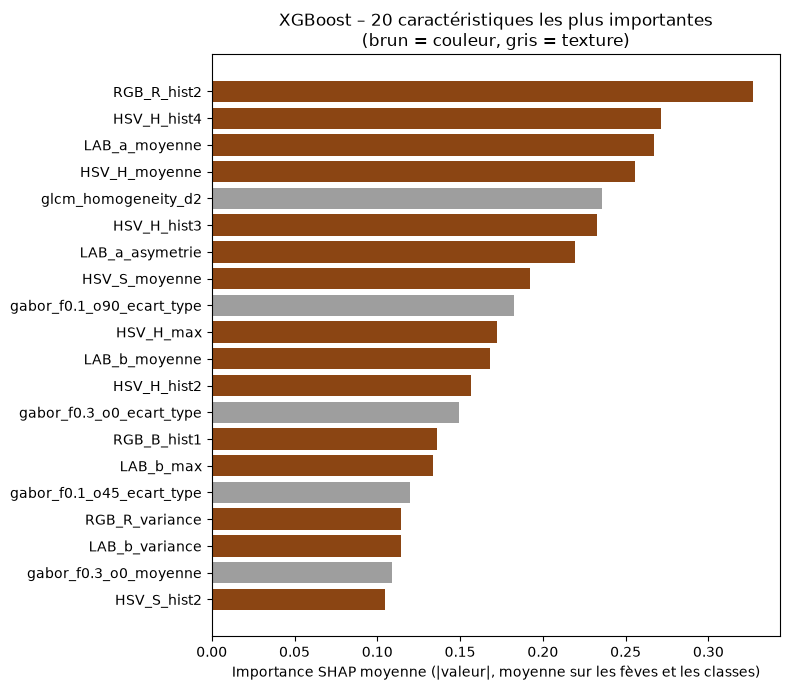

In [7]:
# Importance globale des caractéristiques (SHAP)

import shap

explicateur = shap.TreeExplainer(xgb)
valeurs_shap = explicateur(X_te).values            # forme (894 fèves, 177 caractéristiques, 3 classes)

importance = pd.Series(np.abs(valeurs_shap).mean(axis=(0, 2)), index=M_best.columns).sort_values(ascending=False)
importance.to_csv("../results/tables/08_importance_shap_xgboost.csv")

top = importance.head(20)[::-1]
est_texture = [n.split("_")[0] in ("glcm", "lbp", "gabor") for n in top.index]
plt.figure(figsize=(8, 7))
plt.barh(top.index, top.values, color=["#9E9E9E" if t else "#8B4513" for t in est_texture])
plt.xlabel("Importance SHAP moyenne (|valeur|, moyenne sur les fèves et les classes)")
plt.title("XGBoost – 20 caractéristiques les plus importantes\n(brun = couleur, gris = texture)")
plt.tight_layout()
plt.savefig("../results/figures/08_shap_importance.png", dpi=150)
plt.show()

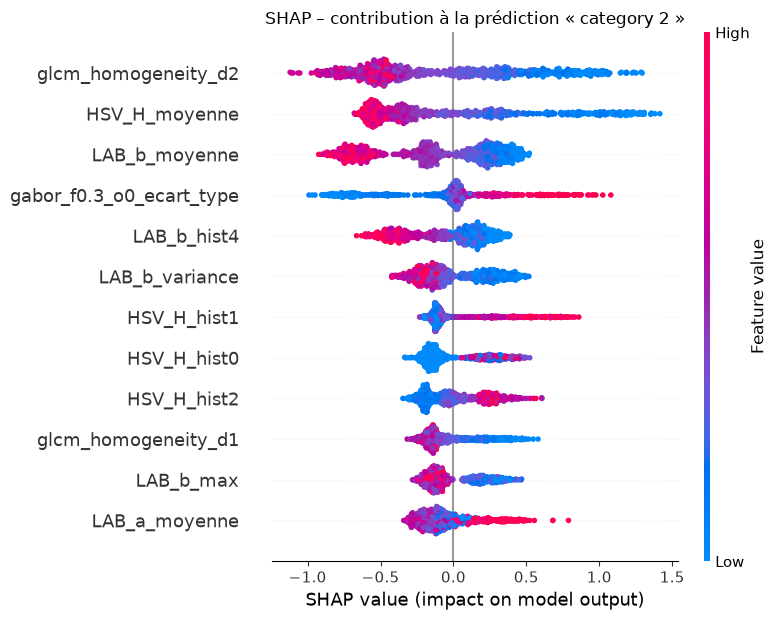

In [8]:
# Comment ces caractéristiques poussent vers la Category 2

plt.figure()
shap.summary_plot(valeurs_shap[:, :, 1], X_te, max_display=12, show=False)
plt.title("SHAP – contribution à la prédiction « category 2 »")
plt.tight_layout()
plt.savefig("../results/figures/08_shap_category2.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# Vérification sur le SVM (importance par permutation)

from sklearn.inspection import permutation_importance

svm = joblib.load("../models/svm_E7_couleur_texture.joblib")["modele"]
perm = permutation_importance(svm, X_te.values, y_test, scoring="f1_macro", n_repeats=5, random_state=42, n_jobs=-1)
importance_svm = pd.Series(perm.importances_mean, index=M_best.columns).sort_values(ascending=False)
importance_svm.to_csv("../results/tables/08_importance_permutation_svm.csv")
importance_svm.head(12).round(4)

glcm_homogeneity_d2          0.0282
gabor_f0.1_o135_moyenne      0.0275
gabor_f0.3_o0_moyenne        0.0245
gabor_f0.2_o90_ecart_type    0.0233
glcm_homogeneity_d1          0.0206
glcm_correlation_d2          0.0197
gabor_f0.3_o0_ecart_type     0.0168
gabor_f0.1_o45_moyenne       0.0158
glcm_correlation_d1          0.0154
gabor_f0.3_o90_moyenne       0.0140
RGB_R_max                    0.0121
LAB_b_aplatissement          0.0104
dtype: float64

**SHAP (XGBoost, F1 = 97,7 %) :**
- **Importance globale :** la couleur domine (15 des 20 caractéristiques les plus importantes), en particulier la **teinte corrigée** (moyenne, maximum et histogramme de H), la composante **a\*** et **b\*** de LAB et la proportion de pixels sombres (`RGB_R_hist2`). La texture contribue aussi (homogénéité GLCM, écarts-types de Gabor), ce qui confirme sa complémentarité avec la couleur.
- **Prédiction de la Category 2 :** elle est favorisée par une teinte basse (violacée après rotation), une faible valeur de b\* (tendance bleue), une forte proportion de pixels dans les teintes violettes, une valeur élevée de a\* et une **faible homogénéité de texture** (surface plus ridée et contrastée).
- Ces résultats confirment l'analyse des espaces de couleur (étape 3) : la Category 2 se distingue par sa **nuance violacée** plus que par sa luminosité, et la correction circulaire de la teinte était indispensable. SHAP montre en plus qu'elle présente une surface moins homogène.

In [10]:
# Importance par groupes de caractéristiques
groupes = {
    "Couleur RGB": [c for c in M_best.columns if c.startswith("RGB_")],
    "Couleur HSV": [c for c in M_best.columns if c.startswith("HSV_")],
    "Couleur LAB": [c for c in M_best.columns if c.startswith("LAB_")],
    "Toute la couleur": [c for c in M_best.columns if c.split("_")[0] in ("RGB", "HSV", "LAB")],
    "Texture GLCM": [c for c in M_best.columns if c.startswith("glcm_")],
    "Texture LBP": [c for c in M_best.columns if c.startswith("lbp_")],
    "Texture Gabor": [c for c in M_best.columns if c.startswith("gabor_")],
    "Toute la texture": [c for c in M_best.columns if c.split("_")[0] in ("glcm", "lbp", "gabor")],
}

f1_reference = f1_score(y_test, svm.predict(X_te.values), average="macro")
rng = np.random.default_rng(42)
lignes = []
for nom, colonnes in groupes.items():
    baisses = []
    for _ in range(5):
        X_melange = X_te.copy()
        ordre = rng.permutation(len(X_melange))
        X_melange[colonnes] = X_te[colonnes].values[ordre]      # tout le groupe mélangé d'un bloc
        baisses.append(f1_reference - f1_score(y_test, svm.predict(X_melange.values), average="macro"))
    lignes.append({"Groupe": nom, "Nb caractéristiques": len(colonnes),
                   "Baisse du F1 (points)": np.mean(baisses) * 100, "Écart-type": np.std(baisses) * 100})

df_groupes = pd.DataFrame(lignes).round(1).sort_values("Baisse du F1 (points)", ascending=False)
df_groupes.to_csv("../results/tables/08_importance_groupes_svm.csv", index=False)
print(f"F1 de référence du SVM : {f1_reference * 100:.1f} %")
df_groupes

F1 de référence du SVM : 98.1 %


,Groupe,Nb caractéristiques,Baisse du F1 (points),Écart-type
3,Toute la couleur,135,54.4,1.5
7,Toute la texture,42,22.4,0.9
2,Couleur LAB,45,13.2,0.9
1,Couleur HSV,45,12.9,0.8
0,Couleur RGB,45,11.7,0.6
6,Texture Gabor,24,10.6,0.6
4,Texture GLCM,8,7.7,0.4
5,Texture LBP,10,1.8,0.5


**Importance par permutation (SVM, F1 de référence 98,1 %) :**
- Caractéristique par caractéristique, la **texture** domine (10 des 12 caractéristiques les plus importantes), alors que SHAP sur XGBoost plaçait la couleur en tête. Ce n'est pas une contradiction : la permutation mesure le caractère **irremplaçable** d'une caractéristique. Les caractéristiques de couleur étant fortement redondantes (teinte, a\*, b\*, histogrammes décrivent la même nuance), en mélanger une seule ne dégrade presque pas le modèle, qui retrouve l'information ailleurs.
- **Par groupes**, la hiérarchie s'inverse : mélanger **toute la couleur** fait chuter le F1 de **54,4 points** (proche du hasard), contre **22,4 points** pour **toute la texture**. Chaque espace de couleur pris isolément coûte 11,7 à 13,2 points ; la somme de ces pertes (≈ 38 points) reste inférieure à la perte totale, ce qui traduit une redondance partielle entre RGB, HSV et LAB.
- Parmi les textures, **Gabor** (10,6 points) et **GLCM** (7,7) sont les plus utiles ; **LBP** n'apporte presque rien (1,8).
- **Conclusion :** la couleur est l'information principale pour classer les fèves, et la texture une information complémentaire indispensable — ce que confirment SHAP, la permutation par groupes et les expériences de l'étape 5.

## Règles floues de l'architecture complète (A7)
Les 8 entrées de la couche ANFIS sont des caractéristiques apprises par le réseau. Pour les interpréter, on mesure leur corrélation avec des caractéristiques manuelles compréhensibles (luminosité, teinte, composantes a\* et b\*, saturation, texture), puis on traduit les centres des règles dominantes en conditions du type « SI … ALORS … ».

In [ ]:
# Quelles règles dominent ?

extracteur_flou = keras.Model(modele_a7.inputs, modele_a7.get_layer("normalisation_floue").output)
entrees_floues = extracteur_flou.predict(X[idx_test], verbose=0)          # (894, 8)
couche_anfis = modele_a7.get_layer("anfis")
forces = np.array(couche_anfis.forces(entrees_floues))                    # (894, 12)
regle_dominante = forces.argmax(axis=1)

lignes = []
for r in range(forces.shape[1]):
    sel = regle_dominante == r
    lignes.append({"Règle": r + 1, "Force moyenne": forces[:, r].mean(), "Fèves où elle domine": sel.sum(),
                   **{f"% {c}": (y_test[sel] == k).mean() * 100 if sel.sum() else np.nan for k, c in enumerate(classes)}})
df_regles_a7 = pd.DataFrame(lignes).round(2)
df_regles_a7.to_csv("../results/tables/08_regles_anfis_A7.csv", index=False)
df_regles_a7

,Règle,Force moyenne,Fèves où elle domine,% category 1,% category 2,% category 3
0,1,0.00,0,NaN,NaN,NaN
1,2,0.02,0,NaN,NaN,NaN
2,3,0.01,0,NaN,NaN,NaN
3,4,0.00,0,NaN,NaN,NaN
4,5,0.33,330,7.88,92.12,0.0
5,6,0.01,0,NaN,NaN,NaN
6,7,0.00,0,NaN,NaN,NaN
7,8,0.00,0,NaN,NaN,NaN
8,9,0.21,176,0.00,0.00,100.0
9,10,0.00,0,NaN,NaN,NaN


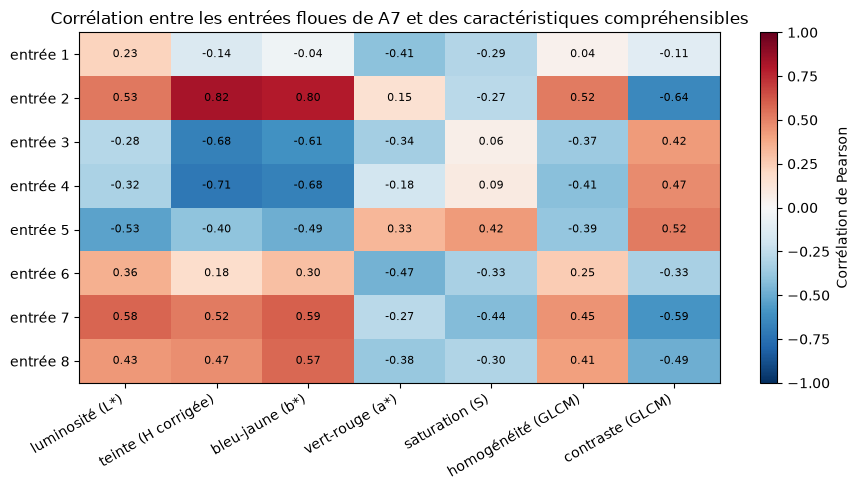

In [12]:
# Caractéristiques manuelles compréhensibles (fèves de test)
reference = pd.DataFrame({
    "luminosité (L*)":     F["couleur"]["LAB_L_moyenne"].values[idx_test],
    "teinte (H corrigée)": F["couleur"]["HSV_H_moyenne"].values[idx_test],
    "bleu-jaune (b*)":     F["couleur"]["LAB_b_moyenne"].values[idx_test],
    "vert-rouge (a*)":     F["couleur"]["LAB_a_moyenne"].values[idx_test],
    "saturation (S)":      F["couleur"]["HSV_S_moyenne"].values[idx_test],
    "homogénéité (GLCM)":  F["glcm"]["glcm_homogeneity_d2"].values[idx_test],
    "contraste (GLCM)":    F["glcm"]["glcm_contrast_d1"].values[idx_test],
})
correlations = pd.DataFrame(
    [[np.corrcoef(entrees_floues[:, j], reference[c])[0, 1] for c in reference.columns]
     for j in range(entrees_floues.shape[1])],
    index=[f"entrée {j + 1}" for j in range(entrees_floues.shape[1])], columns=reference.columns)
correlations.round(2).to_csv("../results/tables/08_correlations_entrees_floues.csv")

plt.figure(figsize=(9, 5))
plt.imshow(correlations.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
plt.xticks(range(correlations.shape[1]), correlations.columns, rotation=30, ha="right")
plt.yticks(range(correlations.shape[0]), correlations.index)
for i in range(correlations.shape[0]):
    for j in range(correlations.shape[1]):
        plt.text(j, i, f"{correlations.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(label="Corrélation de Pearson")
plt.title("Corrélation entre les entrées floues de A7 et des caractéristiques compréhensibles")
plt.tight_layout()
plt.savefig("../results/figures/08_correlations_entrees_floues.png", dpi=150)
plt.show()

Règle 5 (330 fèves) : SI luminosité (L*) basse ET teinte (H corrigée) basse ET bleu-jaune (b*) basse ET contraste (GLCM) élevée
    ALORS category 2  (92 % de fèves de cette classe)

Règle 9 (176 fèves) : SI luminosité (L*) nettement élevée ET teinte (H corrigée) nettement élevée ET bleu-jaune (b*) nettement élevée ET saturation (S) basse ET homogénéité (GLCM) élevée ET contraste (GLCM) nettement basse
    ALORS category 3  (100 % de fèves de cette classe)

Règle 11 (388 fèves) : SI caractéristiques proches de la moyenne
    ALORS category 1  (92 % de fèves de cette classe)



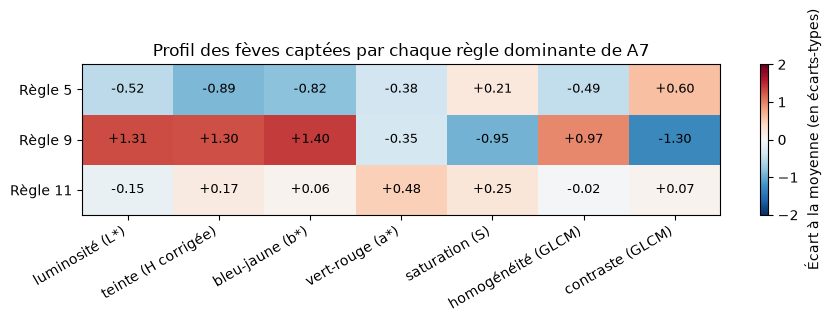

In [14]:
# Décrire chaque règle par les fèves qu’elle capt
from keras import ops

# Profil de chaque règle : caractéristiques moyennes des fèves qu'elle capte, en écarts-types par rapport à la moyenne
z = (reference - reference.mean()) / reference.std()
regles_actives = df_regles_a7[df_regles_a7["Fèves où elle domine"] > 0]["Règle"].values - 1

profils = pd.DataFrame({f"Règle {r + 1}": z[regle_dominante == r].mean() for r in regles_actives}).T
profils.round(2).to_csv("../results/tables/08_profils_regles_A7.csv")

def decrire(valeur):
    if valeur > 1.0:   return "nettement élevée"
    if valeur > 0.5:   return "élevée"
    if valeur < -1.0:  return "nettement basse"
    if valeur < -0.5:  return "basse"
    return None

for r in regles_actives:
    sel = regle_dominante == r
    classe = np.bincount(y_test[sel], minlength=3).argmax()
    purete = (y_test[sel] == classe).mean() * 100
    conditions = [f"{nom} {decrire(v)}" for nom, v in profils.loc[f"Règle {r + 1}"].items() if decrire(v)]
    texte = " ET ".join(conditions) if conditions else "caractéristiques proches de la moyenne"
    print(f"Règle {r + 1} ({sel.sum()} fèves) : SI {texte}\n    ALORS {classes[classe]}  ({purete:.0f} % de fèves de cette classe)\n")

plt.figure(figsize=(9, 3))
plt.imshow(profils.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
plt.xticks(range(profils.shape[1]), profils.columns, rotation=30, ha="right")
plt.yticks(range(profils.shape[0]), profils.index)
for i in range(profils.shape[0]):
    for j in range(profils.shape[1]):
        plt.text(j, i, f"{profils.values[i, j]:+.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(label="Écart à la moyenne (en écarts-types)")
plt.title("Profil des fèves captées par chaque règle dominante de A7")
plt.tight_layout()
plt.savefig("../results/figures/08_profils_regles_A7.png", dpi=150)
plt.show()

**Règles floues de A7 :** comme M8, la couche ANFIS s'organise autour de **trois règles dominantes, une par catégorie**, mais plus pures (92 à 100 %). Leur interprétation directe à partir des centres n'est pas possible, car c'est la position relative des centres qui détermine la règle activée ; on décrit donc chaque règle par le profil des fèves qu'elle capte (écart à la moyenne, en écarts-types).

- **Règle 9 → Category 3 (100 %) :** SI la fève est **claire** (+1,3), **orangée** (teinte +1,3 ; b\* +1,4), **peu saturée** (−0,95) et à **surface lisse** (homogénéité +0,97 ; contraste −1,3).
- **Règle 5 → Category 2 (92 %) :** SI la fève est **sombre** (−0,5), **violacée** (teinte −0,9 ; b\* −0,8) et à **surface contrastée** (+0,6).
- **Règle 11 → Category 1 (92 %) :** SI la fève présente des caractéristiques **proches de la moyenne**, avec une légère tendance rouge (a\* +0,48).

Le modèle a ainsi retrouvé, sans les connaître, les critères mis en évidence par l'analyse des espaces de couleur (étape 3) et par SHAP. La Category 1 apparaît comme une **catégorie intermédiaire** sans critère marqué, ce qui explique que toutes les erreurs se produisent entre les Categories 1 et 2.

## Conclusion de l'étape 8

Les trois méthodes d'interprétabilité convergent :
- **Grad-CAM** montre que l'architecture complète fonde ses décisions sur la fève et non sur le fond ; ses erreurs (toutes entre les Categories 1 et 2) s'accompagnent d'une attention déplacée vers les bords ou les taches sombres.
- **SHAP** et l'**importance par permutation** identifient la couleur — en particulier la teinte corrigée et la composante b\* — comme l'information principale, la texture (Gabor, GLCM) apportant une information complémentaire indispensable ; la forte redondance des caractéristiques de couleur explique les différences entre les deux méthodes.
- Les **règles floues** de A7 se lisent en langage courant : fève claire, orangée et lisse → Category 3 ; fève sombre, violacée et contrastée → Category 2 ; fève intermédiaire → Category 1.

La Category 2 se distingue avant tout par sa **nuance violacée** et sa **surface contrastée**, et la Category 1 occupe une position intermédiaire, à l'origine des confusions observées dans tous les modèles.